# 01 - Exploration, Data Analytics & Cleaning
### Day-ahead forecasting of French hourly electricity demand

**Business context.** Our utility buys electricity on the day-ahead market. Every day **D**, before the auction
closes at **12:00 CET**, the trading desk must know the demand for every hour of day **D+1**. Each MWh of forecast
error is settled later at imbalance prices, and the **evening peaks of cold days** are where errors cost the most.

The French national consumption series is our demand. This first notebook does the unglamorous but decisive work:
**understand the data, prove its quality with statistics, clean it honestly, and frame the problem** the next two
notebooks will model.

**What this notebook delivers**
1. Structural validation of the hourly series (continuity, duplicates, missing values).
2. An honest cleaning step for the few missing values - with the *reason* they are missing.
3. A visual + statistical tour of the demand: distribution, multi-scale seasonality, trend.
4. **Statistical tests** backing every claim: stationarity (ADF / KPSS), autocorrelation (Ljung-Box),
   temperature dependence (Pearson / Spearman), and a significance test on the RTE bias.
5. An audit of **RTE's own day-ahead forecast** - the benchmark we must beat - to find *where* it fails.
6. A fixed, chronological **train / validation / test split** saved for the modelling notebooks.

> **Honesty rule for the whole project.** On day D at 12:00 CET we may only use information available at that
> moment. This notebook builds no forecasting features yet, but the split and the RTE audit are designed around
> that rule so Notebook 2 and 3 inherit a fair playing field.

## 0 - Setup
Libraries, a single consistent visual style, and the data path.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # keep the narrative clean; every statistical test is reported explicitly

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import holidays as holidays_lib

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("Ready - pandas", pd.__version__, "| numpy", np.__version__)

Ready - pandas 3.0.6 | numpy 2.5.2


In [2]:
# ---- One colourblind-safe visual system for every chart (brand-neutral, validated palette) ----
PALETTE = {
    "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
    "violet": "#6250d6", "red": "#e34948", "green": "#0ca30c",
    "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
    "grid": "#e1e0d9", "surface": "#fcfcfb",
}
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
BLUE_CMAP = LinearSegmentedColormap.from_list("brand_blue", BLUE_RAMP)
DIVERGING = LinearSegmentedColormap.from_list(
    "brand_div", ["#184f95", "#86b6ef", "#f0efec", "#eb8f8f", "#c0201f"])

plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "savefig.bbox": "tight",
    "axes.edgecolor": PALETTE["muted"], "axes.linewidth": 0.8,
    "axes.labelcolor": PALETTE["ink2"], "axes.titlecolor": PALETTE["ink"],
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 10, "axes.labelsize": 11,
    "text.color": PALETTE["ink"], "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "xtick.labelcolor": PALETTE["ink2"], "ytick.labelcolor": PALETTE["ink2"],
    "axes.grid": True, "grid.color": PALETTE["grid"], "grid.linewidth": 0.8, "grid.alpha": 0.9,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "legend.frameon": False, "legend.fontsize": 10,
    "figure.dpi": 110, "figure.titlesize": 14, "figure.titleweight": "bold", "lines.linewidth": 1.8,
})

gw_fmt  = FuncFormatter(lambda v, _: f"{v/1000:,.0f}")  # MW -> GW (whole GW, for 30-90 GW scales)
gw1_fmt = FuncFormatter(lambda v, _: f"{v/1000:,.1f}")  # MW -> GW (1 decimal, for ~1 GW error scales)

def titled(ax, title=None, xlabel=None, ylabel=None):
    # consistent left-aligned title + labels
    if title is not None: ax.set_title(title, loc="left")
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    ax.margins(x=0.01)
    return ax

FIG = Path("..") / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Visual style loaded.")

Visual style loaded.


## 1 - Load the raw data and validate its structure
Before any analysis we must trust the time index itself: is it truly hourly, continuous, and free of duplicates?

In [3]:
DATA = Path("..") / "data" / "france_electricity_hourly.csv"
raw = (pd.read_csv(DATA, parse_dates=["datetime_utc"])
         .set_index("datetime_utc")
         .sort_index())

print(f"Rows   : {len(raw):,}")
print(f"Columns: {list(raw.columns)}")
print(f"Span   : {raw.index.min()}  ->  {raw.index.max()}   (tz = {raw.index.tz})")
raw.head()

Rows   : 65,712
Columns: ['load_mw', 'rte_forecast_d1_mw', 'temperature_c']
Span   : 2019-01-01 00:00:00+00:00  ->  2026-06-30 23:00:00+00:00   (tz = UTC)


,load_mw,rte_forecast_d1_mw,temperature_c
datetime_utc,,,
2019-01-01 00:00:00+00:00,"60,826.000","60,837.500",5.850
2019-01-01 01:00:00+00:00,"59,786.500","59,500.000",6.350
2019-01-01 02:00:00+00:00,"56,622.000","56,012.500",5.910
2019-01-01 03:00:00+00:00,"53,919.500","53,300.000",5.700
2019-01-01 04:00:00+00:00,"52,972.000","52,187.500",5.720


**Columns.** `load_mw` is our target (actual French consumption). `rte_forecast_d1_mw` is RTE's public
day-ahead forecast - **the benchmark we must beat**. `temperature_c` is the dominant weather driver.
Storing the index in **UTC** is a deliberate, important choice: it has no duplicated or missing clock hours at
daylight-saving transitions, so the hourly grid is unambiguous. We convert to Paris local time only for
*human-activity* calendar features.

In [4]:
# Rebuild the continuous hourly grid that *should* exist, and compare against reality.
full_idx = pd.date_range(raw.index.min(), raw.index.max(), freq="h", tz="UTC")
missing_hours = full_idx.difference(raw.index)
dup = int(raw.index.duplicated().sum())

pd.DataFrame({
    "check": ["expected hourly rows", "actual rows", "missing hours in grid",
              "duplicate timestamps", "years covered"],
    "result": [f"{len(full_idx):,}", f"{len(raw):,}", f"{len(missing_hours):,}",
               f"{dup:,}", f"{raw.index.min().year}-{raw.index.max().year}"],
})

,check,result
0,expected hourly rows,"65,712"
1,actual rows,"65,712"
2,missing hours in grid,0
3,duplicate timestamps,0
4,years covered,2019-2026


In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
load_mw,"65,705.000","51,502.607","11,016.408","29,364.500","43,333.000","49,780.000","58,746.500","90,233.500"
rte_forecast_d1_mw,"65,705.000","50,831.371","11,048.059","27,712.500","42,600.000","48,962.500","58,062.500","89,975.000"
temperature_c,"65,712.000",13.072,7.023,-5.090,7.920,12.500,17.980,38.520


**Read-out.** The grid is perfectly continuous: **65,712 hourly rows, zero missing timestamps, zero
duplicates**, 7.5 years (2019-01 -> 2026-06). Load ranges ~29-90 GW, temperature -5 to +39 C - all physically
plausible for France, so there are no absurd sensor errors to remove. The only gap is a handful of missing
*values*, which we isolate next.

## 2 - Missing values: find them, explain them, fix them
Good cleaning is not just filling holes - it is understanding *why* they exist so we do not erase real signal.

In [6]:
na = raw[raw.isna().any(axis=1)]
na_local = na.index.tz_convert("Europe/Paris")
print(f"Rows with any missing value: {len(na)}  (out of {len(raw):,}  =  {len(na)/len(raw)*100:.3f}%)")
pd.DataFrame({
    "utc": na.index, "paris_local": na_local, "weekday": na_local.day_name(),
    "load_mw": na["load_mw"].values, "rte_forecast_d1_mw": na["rte_forecast_d1_mw"].values,
    "temperature_c": na["temperature_c"].values,
}).reset_index(drop=True)

Rows with any missing value: 7  (out of 65,712  =  0.011%)


,utc,paris_local,weekday,load_mw,rte_forecast_d1_mw,temperature_c
0,2019-10-27 00:00:00+00:00,2019-10-27 02:00:00+02:00,Sunday,NaN,NaN,15.130
1,2020-10-25 00:00:00+00:00,2020-10-25 02:00:00+02:00,Sunday,NaN,NaN,13.640
2,2021-10-31 00:00:00+00:00,2021-10-31 02:00:00+02:00,Sunday,NaN,NaN,11.860
3,2022-10-30 00:00:00+00:00,2022-10-30 02:00:00+02:00,Sunday,NaN,NaN,14.970
4,2023-10-29 00:00:00+00:00,2023-10-29 02:00:00+02:00,Sunday,NaN,NaN,14.410
5,2024-10-27 00:00:00+00:00,2024-10-27 02:00:00+02:00,Sunday,NaN,NaN,12.970
6,2025-10-26 00:00:00+00:00,2025-10-26 02:00:00+02:00,Sunday,NaN,NaN,8.860


In [7]:
# Hypothesis: every missing row is the last Sunday of October - the autumn DST "fall-back".
last_sun_oct = []
for y in range(raw.index.min().year, raw.index.max().year + 1):
    d = pd.Timestamp(year=y, month=10, day=31)
    while d.weekday() != 6:        # 6 = Sunday
        d -= pd.Timedelta(days=1)
    last_sun_oct.append(d.date())

na_dates = sorted(set(na.index.tz_convert("Europe/Paris").date))
print("Missing dates       :", [str(d) for d in na_dates])
print("Last Sundays of Oct :", [str(d) for d in last_sun_oct if d in na_dates])
print("\nAll missing rows fall exactly on the autumn DST change:",
      set(na_dates).issubset(set(last_sun_oct)))

Missing dates       : ['2019-10-27', '2020-10-25', '2021-10-31', '2022-10-30', '2023-10-29', '2024-10-27', '2025-10-26']
Last Sundays of Oct : ['2019-10-27', '2020-10-25', '2021-10-31', '2022-10-30', '2023-10-29', '2024-10-27', '2025-10-26']

All missing rows fall exactly on the autumn DST change: True


**Diagnosis.** All 7 missing values are single isolated hours, one per year, each on the **last Sunday of
October** - the autumn daylight-saving transition. This is a well-known publication artefact around the clock
change, **not random corruption and not a real demand event**. Because they are isolated single-hour gaps with
healthy neighbours (and temperature is still present), **time interpolation** is the honest, low-risk fix.

In [8]:
# Formalise the hourly grid and impute the 7 DST gaps by time interpolation.
df = raw.reindex(full_idx).copy()
df.index.name = "datetime_utc"

before = df[["load_mw", "rte_forecast_d1_mw"]].isna().sum()
df[["load_mw", "rte_forecast_d1_mw"]] = (
    df[["load_mw", "rte_forecast_d1_mw"]].interpolate(method="time", limit_direction="both"))
after = df[["load_mw", "rte_forecast_d1_mw"]].isna().sum()

print("Missing values  BEFORE :", before.to_dict())
print("Missing values  AFTER  :", after.to_dict())

Missing values  BEFORE : {'load_mw': 7, 'rte_forecast_d1_mw': 7}
Missing values  AFTER  : {'load_mw': 0, 'rte_forecast_d1_mw': 0}


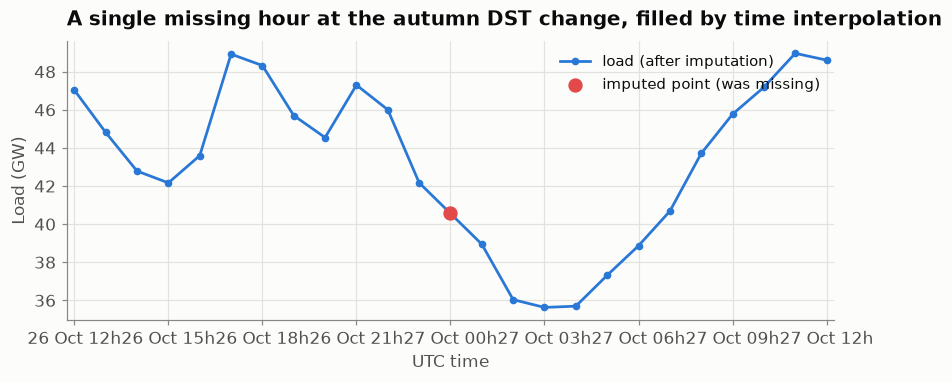

In [9]:
# Visual proof: one DST gap before/after, on a 24h window around 2019-10-27.
win = slice("2019-10-26 12:00", "2019-10-27 12:00")
gap_mask = raw.reindex(full_idx).loc[win, "load_mw"].isna()

fig, ax = plt.subplots(figsize=(9, 3.3))
ax.plot(df.loc[win].index, df.loc[win, "load_mw"], color=PALETTE["blue"], marker="o", ms=4, label="load (after imputation)")
ax.scatter(df.loc[win].index[gap_mask.values], df.loc[win, "load_mw"][gap_mask.values],
           color=PALETTE["red"], s=70, zorder=5, label="imputed point (was missing)")
ax.yaxis.set_major_formatter(gw_fmt)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Hh", tz="UTC"))
ax.legend(loc="upper right")
titled(ax, "A single missing hour at the autumn DST change, filled by time interpolation",
       xlabel="UTC time", ylabel="Load (GW)")
fig.savefig(FIG / "01_dst_imputation.png")
plt.show()

## 3 - Calendar enrichment (Paris local time)
Human activity follows the *local* clock, so seasonality features use Europe/Paris, including French public holidays.

In [10]:
local = df.index.tz_convert("Europe/Paris")
df["hour"]    = local.hour
df["dow"]     = local.dayofweek            # 0 = Monday
df["month"]   = local.month
df["year"]    = local.year
df["is_weekend"] = df["dow"] >= 5

fr_hol = holidays_lib.France(years=range(df["year"].min(), df["year"].max() + 1))
df["is_holiday"] = pd.Series([d in fr_hol for d in local.date], index=df.index)

season_map = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
df["season"] = df["month"].map(season_map)

print("Public holidays flagged:", int(df["is_holiday"].sum()), "hours",
      f"({df['is_holiday'].mean()*100:.1f}% of rows)")
df[["load_mw", "rte_forecast_d1_mw", "temperature_c", "hour", "dow", "season", "is_weekend", "is_holiday"]].head()

Public holidays flagged: 1991 hours (3.0% of rows)


,load_mw,rte_forecast_d1_mw,temperature_c,hour,dow,season,is_weekend,is_holiday
datetime_utc,,,,,,,,
2019-01-01 00:00:00+00:00,"60,826.000","60,837.500",5.850,1,1,Winter,False,True
2019-01-01 01:00:00+00:00,"59,786.500","59,500.000",6.350,2,1,Winter,False,True
2019-01-01 02:00:00+00:00,"56,622.000","56,012.500",5.910,3,1,Winter,False,True
2019-01-01 03:00:00+00:00,"53,919.500","53,300.000",5.700,4,1,Winter,False,True
2019-01-01 04:00:00+00:00,"52,972.000","52,187.500",5.720,5,1,Winter,False,True


## 4 - The demand series at a glance
Seven and a half years of hourly load, shown as a daily mean so the structure is legible.

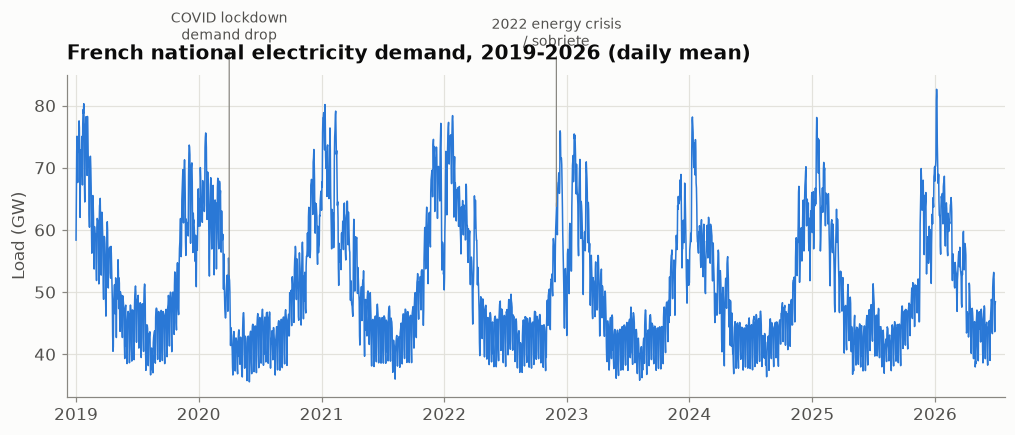

In [11]:
daily = df["load_mw"].resample("D").mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.index, daily.values, color=PALETTE["blue"], lw=1.0)
ax.yaxis.set_major_formatter(gw_fmt)

# annotate two real regime effects (NOT data errors - we must keep them)
for when, text, dy in [("2020-04-01", "COVID lockdown\ndemand drop", 8),
                       ("2022-12-01", "2022 energy crisis\n/ sobriete", 7)]:
    x = pd.Timestamp(when, tz="UTC")
    ax.annotate(text, xy=(x, daily.loc[:x].iloc[-1]), xytext=(x, daily.max() + dy * 1000),
                color=PALETTE["ink2"], fontsize=9, ha="center",
                arrowprops=dict(arrowstyle="-", color=PALETTE["muted"], lw=0.8))
titled(ax, "French national electricity demand, 2019-2026 (daily mean)",
       xlabel="", ylabel="Load (GW)")
fig.savefig(FIG / "02_overview.png")
plt.show()

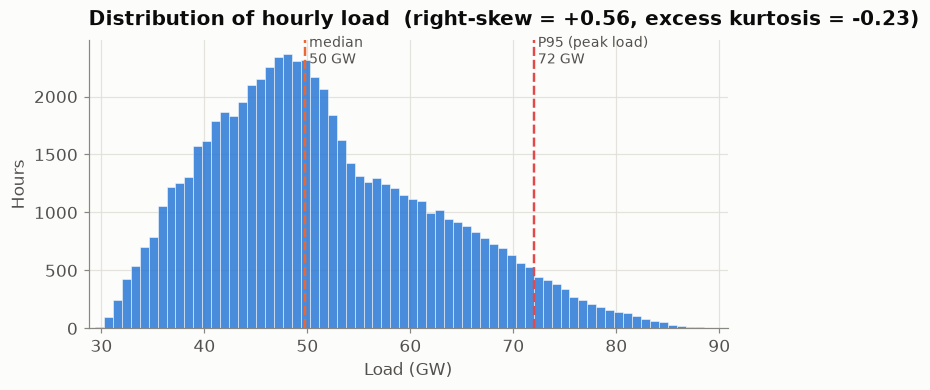

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(df["load_mw"], bins=70, color=PALETTE["blue"], alpha=0.85, edgecolor=PALETTE["surface"], linewidth=0.4)
for q, lab in [(0.5, "median"), (0.95, "P95 (peak load)")]:
    v = df["load_mw"].quantile(q)
    ax.axvline(v, color=PALETTE["orange"] if q == 0.5 else PALETTE["red"], lw=1.6, ls="--")
    ax.text(v, ax.get_ylim()[1]*0.92, f" {lab}\n {v/1000:,.0f} GW", color=PALETTE["ink2"], fontsize=9)
ax.xaxis.set_major_formatter(gw_fmt)
sk, ku = stats.skew(df["load_mw"]), stats.kurtosis(df["load_mw"])
titled(ax, f"Distribution of hourly load  (right-skew = {sk:+.2f}, excess kurtosis = {ku:+.2f})",
       xlabel="Load (GW)", ylabel="Hours")
fig.savefig(FIG / "03_distribution.png")
plt.show()

The distribution is **right-skewed**: most hours sit near the median (~50 GW) but a long upper tail reaches
~90 GW. That tail is the **cold-snap evening peak** - rare hours, but exactly where imbalance costs concentrate.
A good forecaster must earn its keep in that tail, not just on average.

## 5 - Multi-scale seasonality
Electricity demand is driven by human routines and weather, producing three nested cycles: daily, weekly, yearly.

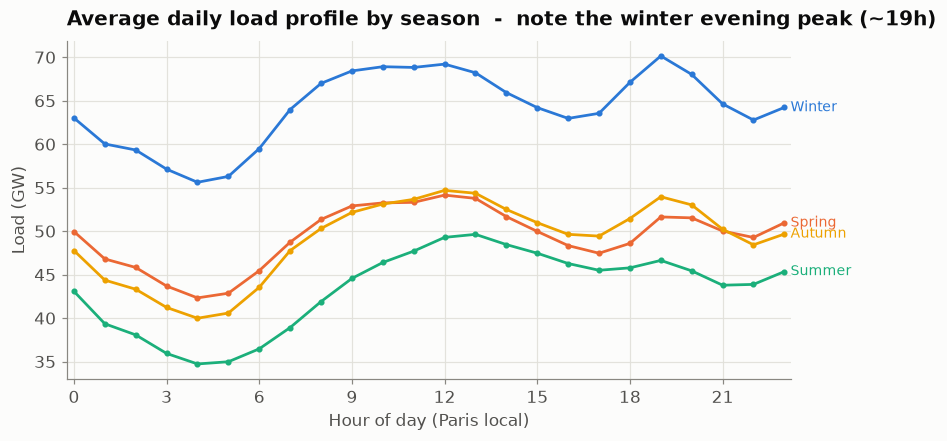

In [13]:
# 5a - Average daily shape by season (hour of day, local time)
prof = df.groupby(["season", "hour"])["load_mw"].mean().unstack(0)
order  = ["Winter", "Spring", "Summer", "Autumn"]
colors = {"Winter": PALETTE["blue"], "Spring": PALETTE["orange"],
          "Summer": PALETTE["aqua"], "Autumn": PALETTE["yellow"]}

fig, ax = plt.subplots(figsize=(8.5, 4))
for s in order:
    ax.plot(prof.index, prof[s], color=colors[s], label=s, marker="o", ms=3)
    ax.text(23.2, prof[s].iloc[-1], s, color=colors[s], fontsize=9, va="center")  # direct labels
ax.yaxis.set_major_formatter(gw_fmt)
ax.set_xticks(range(0, 24, 3))
titled(ax, "Average daily load profile by season  -  note the winter evening peak (~19h)",
       xlabel="Hour of day (Paris local)", ylabel="Load (GW)")
fig.savefig(FIG / "04_daily_profile.png")
plt.show()

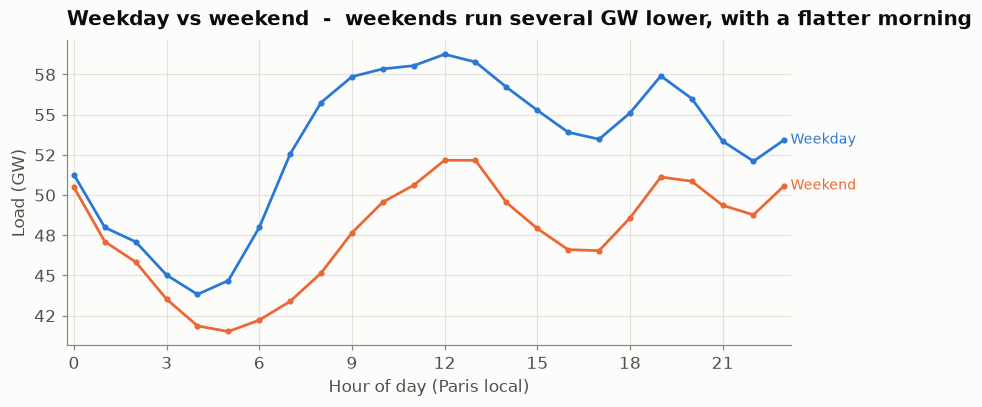

In [14]:
# 5b - Weekday vs weekend daily shape
wk = (df.assign(kind=np.where(df["is_weekend"], "Weekend", "Weekday"))
        .groupby(["kind", "hour"])["load_mw"].mean().unstack(0))
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for kind, c in [("Weekday", PALETTE["blue"]), ("Weekend", PALETTE["orange"])]:
    ax.plot(wk.index, wk[kind], color=c, marker="o", ms=3, label=kind)
    ax.text(23.2, wk[kind].iloc[-1], kind, color=c, fontsize=9, va="center")
ax.yaxis.set_major_formatter(gw_fmt)
ax.set_xticks(range(0, 24, 3))
titled(ax, "Weekday vs weekend  -  weekends run several GW lower, with a flatter morning",
       xlabel="Hour of day (Paris local)", ylabel="Load (GW)")
fig.savefig(FIG / "05_weekday_weekend.png")
plt.show()

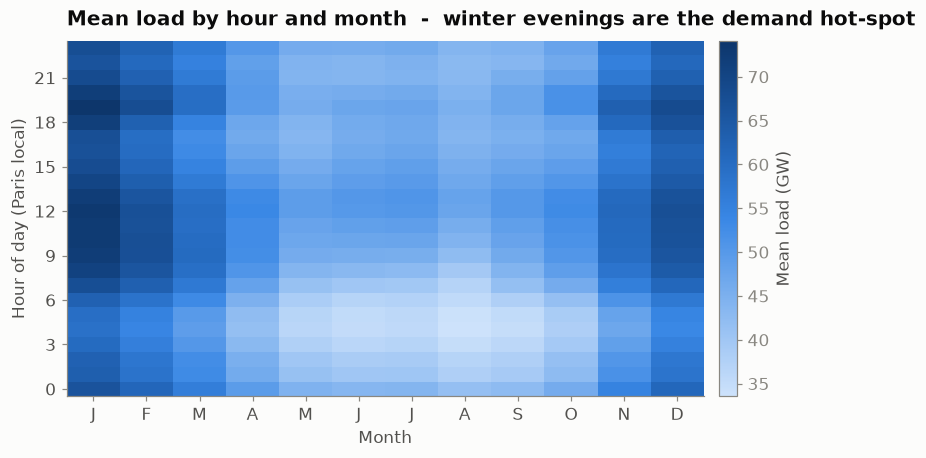

In [15]:
# 5c - Hour x Month heatmap (the whole seasonal story in one panel)
hm = df.groupby(["hour", "month"])["load_mw"].mean().unstack("month") / 1000  # GW
fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(hm.values, aspect="auto", origin="lower", cmap=BLUE_CMAP)
ax.set_xticks(range(12)); ax.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
ax.set_yticks(range(0, 24, 3)); ax.set_yticklabels(range(0, 24, 3))
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("Mean load (GW)", color=PALETTE["ink2"])
cb.ax.tick_params(colors=PALETTE["muted"])
titled(ax, "Mean load by hour and month  -  winter evenings are the demand hot-spot",
       xlabel="Month", ylabel="Hour of day (Paris local)")
fig.savefig(FIG / "06_hour_month_heatmap.png")
plt.show()

**Three cycles, one picture.** The heatmap concentrates the story: demand peaks in **winter evenings**
(top-left / top-right corners) and troughs on **summer nights**. The daily profile shows the morning ramp and the
sharp **~19h winter peak**; weekends sit several GW below weekdays. These are the cycles any model must capture -
and they motivate the seasonal terms (daily = 24h, weekly = 168h) we test next.

## 6 - Decomposition & stationarity (statistical backing)
We separate trend / seasonal / remainder with STL, then test stationarity formally with ADF and KPSS.

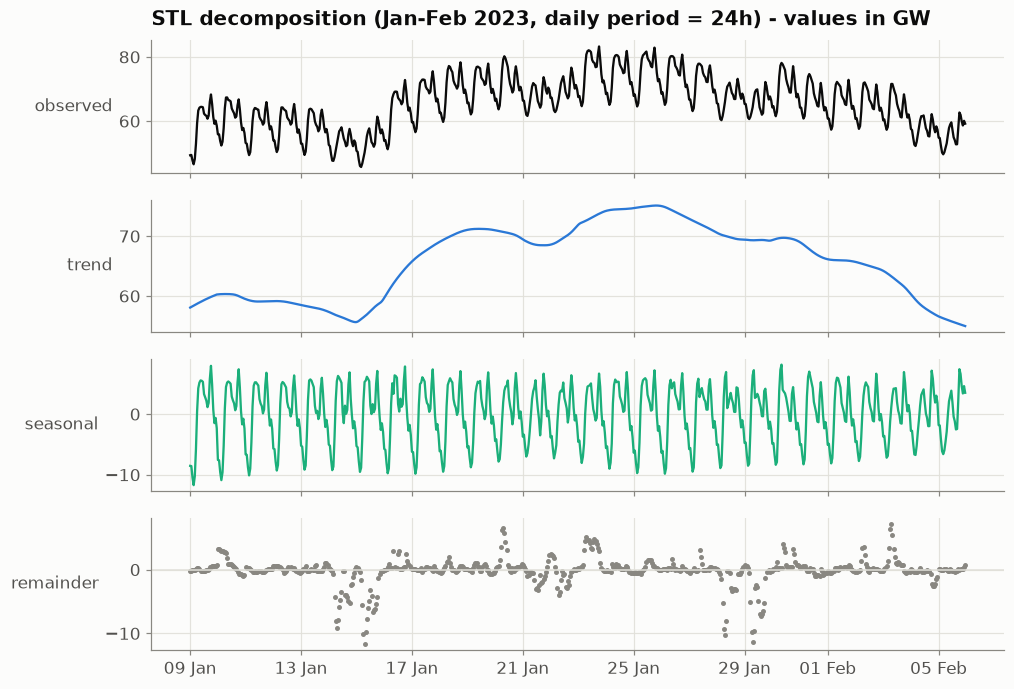

In [16]:
# STL on a readable 4-week window (period = 24h) to visualise the daily cycle + slow trend
stl_win = df.loc["2023-01-09":"2023-02-05", "load_mw"]
res = STL(stl_win, period=24, robust=True).fit()
comp = pd.DataFrame({"observed": res.observed, "trend": res.trend,
                     "seasonal": res.seasonal, "remainder": res.resid})

fig, axes = plt.subplots(4, 1, figsize=(10, 7.2), sharex=True)
parts = [("observed", PALETTE["ink"]), ("trend", PALETTE["blue"]),
         ("seasonal", PALETTE["aqua"]), ("remainder", PALETTE["muted"])]
for ax, (col, c) in zip(axes, parts):
    if col == "remainder":
        ax.axhline(0, color=PALETTE["grid"], lw=1)
        ax.scatter(comp.index, comp[col] / 1000, s=5, color=c)
    else:
        ax.plot(comp.index, comp[col] / 1000, color=c, lw=1.5)
    ax.set_ylabel(col, rotation=0, ha="right", va="center", color=PALETTE["ink2"])
axes[0].set_title("STL decomposition (Jan-Feb 2023, daily period = 24h) - values in GW", loc="left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.savefig(FIG / "07_stl.png")
plt.show()

In [17]:
# Stationarity tests. ADF H0 = has a unit root (non-stationary). KPSS H0 = stationary.
def stationarity(series, name):
    s = pd.Series(series).dropna()
    if len(s) > 20000:                       # ADF autolag is costly; a 3-year slice is representative
        s = s.iloc[-20000:]
    adf = adfuller(s, autolag="AIC")
    kp  = kpss(s, regression="c", nlags="auto")
    return {
        "series": name,
        "ADF stat": round(adf[0], 2), "ADF p": round(adf[1], 4),
        "ADF -> ": "stationary" if adf[1] < 0.05 else "unit root",
        "KPSS stat": round(kp[0], 3), "KPSS p": round(kp[1], 4),
        "KPSS -> ": "stationary" if kp[1] > 0.05 else "non-stationary",
    }

load = df["load_mw"]
stat_tbl = pd.DataFrame([
    stationarity(load,                      "load (raw)"),
    stationarity(load.diff(1),              "diff-1 (hourly)"),
    stationarity(load.diff(24),             "diff-24 (seasonal)"),
    stationarity(load.diff(24).diff(1),     "diff-24 then diff-1"),
])
stat_tbl

C:\Users\marouane.housni\AppData\Local\Temp\ipykernel_14708\1017054417.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp  = kpss(s, regression="c", nlags="auto")


C:\Users\marouane.housni\AppData\Local\Temp\ipykernel_14708\1017054417.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp  = kpss(s, regression="c", nlags="auto")


C:\Users\marouane.housni\AppData\Local\Temp\ipykernel_14708\1017054417.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp  = kpss(s, regression="c", nlags="auto")


C:\Users\marouane.housni\AppData\Local\Temp\ipykernel_14708\1017054417.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp  = kpss(s, regression="c", nlags="auto")


,series,ADF stat,ADF p,ADF ->,KPSS stat,KPSS p,KPSS ->
0,load (raw),-5.490,0.000,stationary,1.675,0.010,non-stationary
1,diff-1 (hourly),-22.630,0.000,stationary,0.042,0.100,stationary
2,diff-24 (seasonal),-23.400,0.000,stationary,0.012,0.100,stationary
3,diff-24 then diff-1,-33.610,0.000,stationary,0.001,0.100,stationary


**How to read this.** The two tests have *opposite* null hypotheses, so agreement is informative. On the
**raw** series ADF often rejects a unit root (strong periodic mean-reversion looks "stationary"), yet **KPSS
rejects stationarity** because of the slow trend and seasonal mean shifts - the classic signature of a series that
needs differencing. After **seasonal differencing (lag 24)** - optionally combined with a first difference - both
tests agree the series is stationary. This is the empirical justification for the **seasonal (S)ARIMA** orders we
calibrate in Notebook 2.

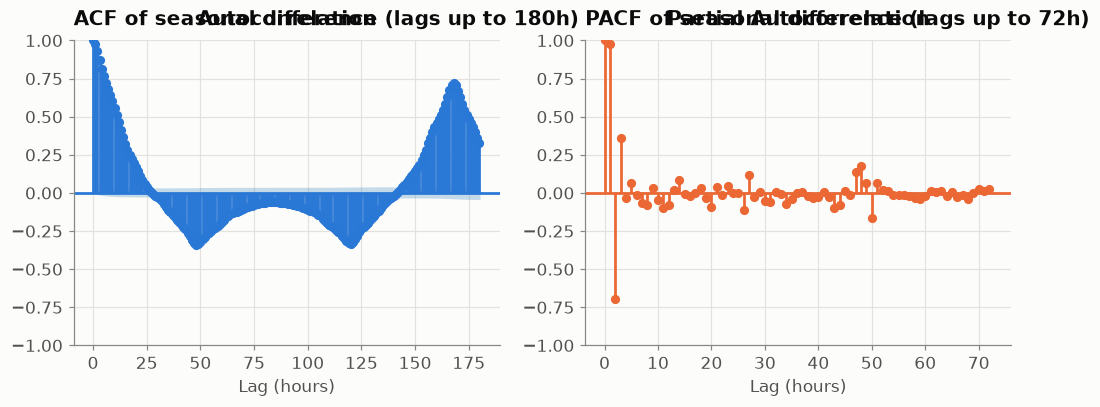

In [18]:
# ACF / PACF - which lags carry memory? (computed on the stationarity-friendly seasonal difference)
d = df["load_mw"].diff(24).dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_acf(d, lags=180, ax=axes[0], color=PALETTE["blue"], vlines_kwargs={"colors": PALETTE["blue"]})
plot_pacf(d, lags=72, ax=axes[1], method="ywm", color=PALETTE["orange"], vlines_kwargs={"colors": PALETTE["orange"]})
axes[0].set_title("ACF of seasonal difference (lags up to 180h)", loc="left")
axes[1].set_title("PACF of seasonal difference (lags up to 72h)", loc="left")
for ax in axes: ax.set_xlabel("Lag (hours)")
fig.savefig(FIG / "08_acf_pacf.png")
plt.show()

In [19]:
# Ljung-Box: is there autocorrelation to exploit? (tiny p = yes, strongly)
lb = acorr_ljungbox(df["load_mw"], lags=[1, 24, 168], return_df=True)
lb.index.name = "lag (h)"
print("Ljung-Box on load - H0 = no autocorrelation:")
print(lb.to_string())
print("\nInterpretation: p-values are ~0 at 1h, 24h and 168h -> strong daily and weekly memory.")

Ljung-Box on load - H0 = no autocorrelation:
              lb_stat  lb_pvalue
lag (h)                         
1          63,352.521      0.000
24      1,046,821.539      0.000
168     5,812,328.389      0.000

Interpretation: p-values are ~0 at 1h, 24h and 168h -> strong daily and weekly memory.


**Backing.** ACF spikes at multiples of **24h and 168h**; the PACF cuts off after a few low-order and
seasonal lags. Ljung-Box returns p ~ 0 at lags 1, 24 and 168 - demand is highly autocorrelated at the hourly,
daily and weekly scales. There is abundant structure for both SARIMA and lag-based ML models to capture.

## 7 - Temperature: the dominant exogenous driver
Heating below ~15 C and cooling above ~20 C make the load-temperature relationship a non-linear 'hockey stick'.

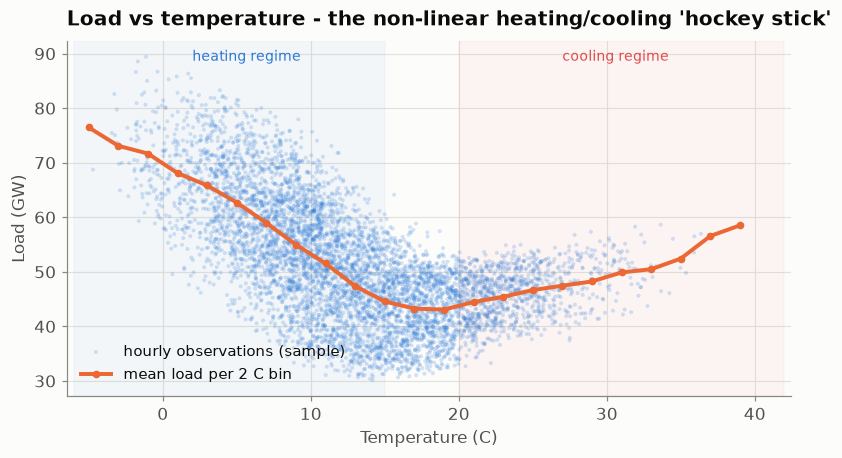

In [20]:
samp = df.sample(min(6000, len(df)), random_state=0)
bins = pd.cut(df["temperature_c"], np.arange(-6, 42, 2))
binned = df.groupby(bins, observed=True)["load_mw"].mean()
centers = [iv.mid for iv in binned.index]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.scatter(samp["temperature_c"], samp["load_mw"], s=7, alpha=0.20, color=PALETTE["blue"],
           edgecolors="none", label="hourly observations (sample)")
ax.plot(centers, binned.values, color=PALETTE["orange"], lw=2.6, marker="o", ms=4, label="mean load per 2 C bin")
ax.axvspan(-6, 15, color=PALETTE["blue"], alpha=0.04)
ax.axvspan(20, 42, color=PALETTE["red"], alpha=0.04)
ax.text(2, ax.get_ylim()[1]*0.96, "heating regime", color=PALETTE["blue"], fontsize=9)
ax.text(27, ax.get_ylim()[1]*0.96, "cooling regime", color=PALETTE["red"], fontsize=9)
ax.yaxis.set_major_formatter(gw_fmt)
ax.legend(loc="lower left")
titled(ax, "Load vs temperature - the non-linear heating/cooling 'hockey stick'",
       xlabel="Temperature (C)", ylabel="Load (GW)")
fig.savefig(FIG / "09_load_vs_temp.png")
plt.show()

In [21]:
# Correlation tests. Pearson = linear; Spearman = monotone. A single coefficient cannot capture a V-shape,
# so we also test physically-motivated degree-day transforms (heating below 15 C, cooling above 20 C).
pr, pp = stats.pearsonr(df["temperature_c"], df["load_mw"])
sr, sp = stats.spearmanr(df["temperature_c"], df["load_mw"])
hdd = np.maximum(15 - df["temperature_c"], 0)
cdd = np.maximum(df["temperature_c"] - 20, 0)
pr_h, _ = stats.pearsonr(hdd, df["load_mw"])
pr_c, _ = stats.pearsonr(cdd, df["load_mw"])

print("Raw temperature vs load:")
print(f"  Pearson  r = {pr:+.3f}   (linear,   p = {pp:.0e})")
print(f"  Spearman r = {sr:+.3f}   (monotone, p = {sp:.0e})")
print("\nAfter a physically-motivated degree-day transform:")
print(f"  Pearson(load, Heating-Degree base 15 C) = {pr_h:+.3f}   <- much stronger than raw temperature")
print(f"  Pearson(load, Cooling-Degree base 20 C) = {pr_c:+.3f}   <- weak: France is heating-dominated")
print("\nThe raw linear r understates the link because the relationship is V-shaped. The heating-degree")
print("transform recovers a strong signal - which is why Notebook 2 engineers degree-day features.")

Raw temperature vs load:
  Pearson  r = -0.605   (linear,   p = 0e+00)
  Spearman r = -0.631   (monotone, p = 0e+00)

After a physically-motivated degree-day transform:
  Pearson(load, Heating-Degree base 15 C) = +0.716   <- much stronger than raw temperature
  Pearson(load, Cooling-Degree base 20 C) = -0.124   <- weak: France is heating-dominated

The raw linear r understates the link because the relationship is V-shaped. The heating-degree
transform recovers a strong signal - which is why Notebook 2 engineers degree-day features.


## 8 - Auditing the RTE benchmark (framing question 1)
RTE's public day-ahead forecast is the bar to beat. We measure its error honestly and, crucially, find **where**
it fails - because that is where our model can add value.

In [22]:
df["rte_err"]     = df["load_mw"] - df["rte_forecast_d1_mw"]   # +ve => RTE under-forecast
df["rte_abs_err"] = df["rte_err"].abs()

def score(y, yhat):
    e = y - yhat
    return pd.Series({"MAE_MW": e.abs().mean(), "RMSE_MW": np.sqrt((e**2).mean()),
                      "MAPE_%": (e.abs() / y).mean() * 100, "Bias_MW": e.mean()})

rte_scores = score(df["load_mw"], df["rte_forecast_d1_mw"])
print("RTE day-ahead forecast error (full history):")
print(rte_scores.to_string())
print(f"\nThat MAPE of {rte_scores['MAPE_%']:.2f}% is a strong benchmark - beating it HONESTLY is the real challenge.")

RTE day-ahead forecast error (full history):
MAE_MW    1,143.518
RMSE_MW   1,490.983
MAPE_%        2.251
Bias_MW     671.466

That MAPE of 2.25% is a strong benchmark - beating it HONESTLY is the real challenge.


In [23]:
# Is the +Bias (RTE under-forecast) statistically real, or noise?
t, p = stats.ttest_1samp(df["rte_err"].dropna(), 0)
ci = stats.t.interval(0.95, len(df["rte_err"].dropna()) - 1,
                      loc=df["rte_err"].mean(), scale=stats.sem(df["rte_err"].dropna()))
print(f"One-sample t-test on mean RTE error (H0: bias = 0):  t = {t:,.1f},  p = {p:.1e}")
print(f"Mean error = {df['rte_err'].mean():+,.0f} MW,  95% CI = [{ci[0]:+,.0f}, {ci[1]:+,.0f}] MW")
print("\n-> RTE systematically UNDER-forecasts by a small but highly significant margin: a bias our model can remove.")

# Is there exploitable autocorrelation left in RTE's residuals?
lb_r = acorr_ljungbox(df["rte_err"].dropna(), lags=[24, 168], return_df=True)
print("\nLjung-Box on RTE residuals (H0: no autocorrelation):")
print(lb_r.to_string())

One-sample t-test on mean RTE error (H0: bias = 0):  t = 129.3,  p = 0.0e+00
Mean error = +671 MW,  95% CI = [+661, +682] MW

-> RTE systematically UNDER-forecasts by a small but highly significant margin: a bias our model can remove.



Ljung-Box on RTE residuals (H0: no autocorrelation):
        lb_stat  lb_pvalue
24  277,571.276      0.000
168 622,889.862      0.000


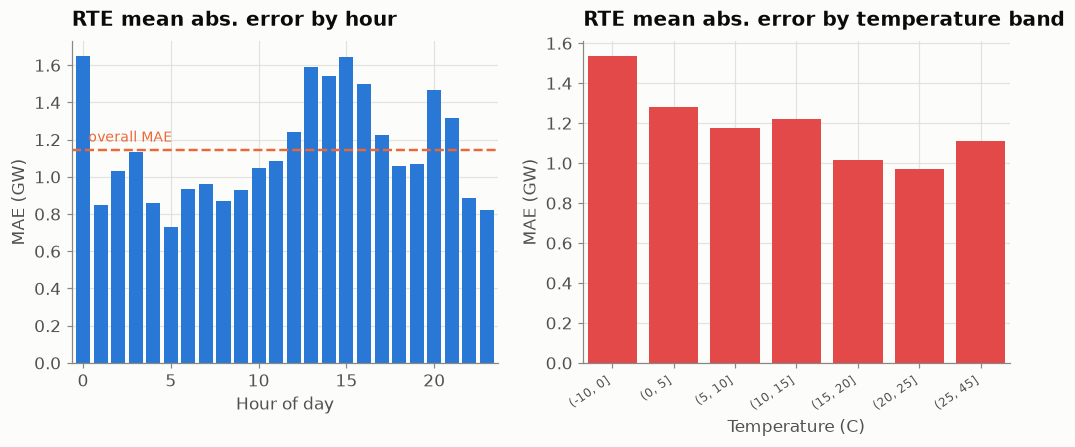

In [24]:
# WHERE does RTE fail? By hour of day and by temperature band.
by_hour = df.groupby("hour")["rte_abs_err"].mean()
tband = pd.cut(df["temperature_c"], [-10, 0, 5, 10, 15, 20, 25, 45])
by_temp = df.groupby(tband, observed=True)["rte_abs_err"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(by_hour.index, by_hour.values, color=PALETTE["blue"], width=0.8)
axes[0].axhline(rte_scores["MAE_MW"], color=PALETTE["orange"], lw=1.6, ls="--")
axes[0].text(0.3, rte_scores["MAE_MW"]*1.04, "overall MAE", color=PALETTE["orange"], fontsize=9)
axes[0].yaxis.set_major_formatter(gw1_fmt)
titled(axes[0], "RTE mean abs. error by hour", xlabel="Hour of day", ylabel="MAE (GW)")

axes[1].bar(range(len(by_temp)), by_temp.values, color=PALETTE["red"], width=0.8)
axes[1].set_xticks(range(len(by_temp)))
axes[1].set_xticklabels([str(iv) for iv in by_temp.index], rotation=35, ha="right", fontsize=8)
axes[1].yaxis.set_major_formatter(gw1_fmt)
titled(axes[1], "RTE mean abs. error by temperature band", xlabel="Temperature (C)", ylabel="MAE (GW)")
fig.savefig(FIG / "10_rte_error_breakdown.png")
plt.show()

**Where RTE struggles - our opportunity.** Errors are largest in the **evening peak hours** and at the
**temperature extremes** (cold snaps especially). RTE also carries a small but statistically significant
**under-forecast bias**, and its residuals remain autocorrelated at 24h/168h (Ljung-Box p ~ 0) - meaning there is
**structure left on the table**. A model that removes the bias and sharpens cold-evening predictions is exactly
how we can beat this benchmark where it matters most financially.

## 9 - A fixed, honest evaluation split
All models in Notebooks 2 & 3 are trained, tuned and judged on the **same chronological split** - never shuffled,
so no future information leaks into the past.

In [25]:
df["split"] = np.select([df["year"] <= 2023, df["year"] == 2024],
                        ["train", "val"], default="test")
g = df.reset_index().groupby("split")
span = pd.DataFrame({"from": g["datetime_utc"].min().dt.date,
                     "to":   g["datetime_utc"].max().dt.date,
                     "hours": g.size()})
span["years"] = (span["hours"] / 8760).round(2)
span = span.reindex(["train", "val", "test"])
print(span.to_string())

             from          to  hours  years
split                                      
train  2019-01-01  2023-12-31  43823  5.000
val    2023-12-31  2024-12-31   8784  1.000
test   2024-12-31  2026-06-30  13105  1.500


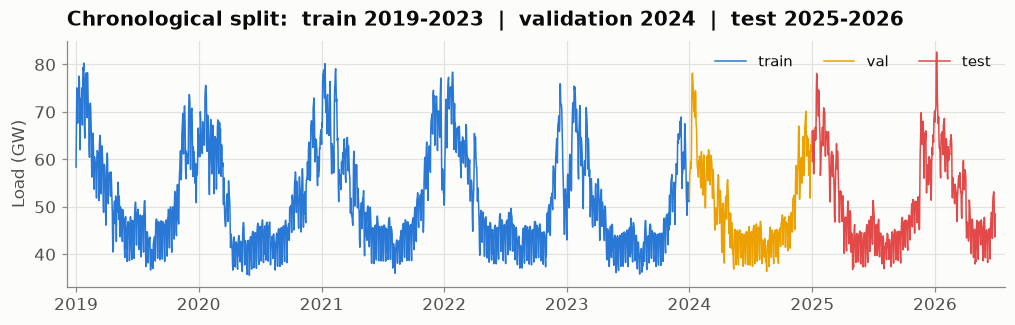

In [26]:
# Timeline coloured by split (daily mean)
split_daily = df["split"].resample("D").first()
fig, ax = plt.subplots(figsize=(11, 2.9))
cmap = {"train": PALETTE["blue"], "val": PALETTE["yellow"], "test": PALETTE["red"]}
for name, c in cmap.items():
    mask = split_daily.reindex(daily.index) == name
    ax.plot(daily.index[mask.values], daily.values[mask.values], color=c, lw=1.0, label=name)
ax.yaxis.set_major_formatter(gw_fmt)
ax.legend(loc="upper right", ncol=3)
titled(ax, "Chronological split:  train 2019-2023  |  validation 2024  |  test 2025-2026",
       xlabel="", ylabel="Load (GW)")
fig.savefig(FIG / "11_split_timeline.png")
plt.show()

**Why this split.** Train (2019-2023) covers COVID and the 2022 energy crisis, so the models see varied
regimes. Validation (2024) is for model selection and hyper-parameters. Test (2025 - 2026-06) is a **locked box**
opened only for the final, honest scorecard in Notebook 3. Chronological order mirrors real operations: we always
predict the future from the past.

## 10 - Persist the cleaned dataset
Saved as Parquet (keeps the tz-aware index and dtypes) for Notebooks 2 & 3 to load directly.

In [27]:
proc = Path("..") / "data" / "processed"
proc.mkdir(parents=True, exist_ok=True)
out_path = proc / "france_clean_hourly.parquet"

keep = ["load_mw", "rte_forecast_d1_mw", "temperature_c",
        "hour", "dow", "month", "year", "is_weekend", "is_holiday", "season", "split"]
df[keep].to_parquet(out_path)
print(f"Saved {len(df):,} rows -> {out_path}")
print("Columns:", keep)
pd.read_parquet(out_path).head(3)

Saved 65,712 rows -> ..\data\processed\france_clean_hourly.parquet
Columns: ['load_mw', 'rte_forecast_d1_mw', 'temperature_c', 'hour', 'dow', 'month', 'year', 'is_weekend', 'is_holiday', 'season', 'split']


,load_mw,rte_forecast_d1_mw,temperature_c,hour,dow,month,year,is_weekend,is_holiday,season,split
datetime_utc,,,,,,,,,,,
2019-01-01 00:00:00+00:00,"60,826.000","60,837.500",5.850,1,1,1,2019,False,True,Winter,train
2019-01-01 01:00:00+00:00,"59,786.500","59,500.000",6.350,2,1,1,2019,False,True,Winter,train
2019-01-01 02:00:00+00:00,"56,622.000","56,012.500",5.910,3,1,1,2019,False,True,Winter,train


## 11 - Summary of findings

**Data quality - excellent.**
- 65,712 hourly rows, 2019-01 -> 2026-06, **no missing hours, no duplicates**.
- Only **7 missing values (0.011%)**, all on the autumn DST change - imputed by time interpolation.
- No implausible values; COVID (2020) and the 2022 energy crisis are **kept** as real regime effects.

**Structure - rich and learnable.**
- Strong **daily (24h)** and **weekly (168h)** seasonality plus a **winter annual peak**; Ljung-Box p ~ 0 at all three.
- KPSS + ADF agree the raw series is non-stationary but becomes stationary after **seasonal (lag-24) differencing** -> SARIMA orders justified.
- Temperature is the dominant driver through a **non-linear heating/cooling** relationship -> motivates degree-day features.

**The benchmark - strong but beatable where it counts.**
- RTE day-ahead: **MAE ~ 1.14 GW, RMSE ~ 1.49 GW, MAPE ~ 2.25%**.
- A small but **statistically significant under-forecast bias** (+0.67 GW, t-test p ~ 0) and **autocorrelated residuals** -> exploitable.
- Errors concentrate in **evening peaks** and **temperature extremes** - the financially expensive hours.

**Set up for honest modelling.**
- Fixed chronological split (train 2019-2023 / val 2024 / test 2025-2026) and a clean Parquet dataset saved.

**Next - Notebook 2:** engineer cut-off-respecting features and benchmark a ladder of models
(seasonal-naive -> Holt-Winters -> SARIMA/SARIMAX -> XGBoost/LightGBM) against RTE under the day-ahead protocol.